# MuJoCo ramp-up

A short, hands-on introduction to [MuJoCo](https://mujoco.org) in Python. By the end you will know how to:

1. **Start a simulation**: load a model and step physics.
2. **Read data**: joint angles, velocities, body positions, sensors.
3. **Actuate**: send commands to motors and servos, and write a control loop.
4. **Render**: get images and short videos out of the simulator.
5. Do all of the above on a real robot model: the **Shadow Hand** used by this repo.

Run the cells top to bottom (`Shift+Enter`). Each section ends with a 🧪 **Try it** box with small changes to make.

---

## 0. The three things you need to know

Almost all MuJoCo code uses three objects:

| Object | What it is | Changes during simulation? |
|---|---|---|
| `mujoco.MjModel` | The **description** of the world: bodies, joints, masses, actuators, timestep… Built from an XML file. | No (constant) |
| `mujoco.MjData` | The **state** of the world: positions, velocities, controls, forces, time… | Yes, every step |
| `mujoco.mj_step(model, data)` | Advances `data` by one timestep (`model.opt.timestep`). | — |

```
            ┌──────────────┐            
  XML ───▶  │   MjModel    │  (constant)
            └──────┬───────┘            
                   │                    
  data.ctrl ──▶ mj_step(model, data) ──▶ data.qpos, data.qvel, data.sensordata, ...
  (you write)                             (you read)
```

A simulation is a loop: **write `data.ctrl` → `mj_step` → read `data`** → repeat.

In [1]:
import io
import os
import sys

# Offscreen rendering backend. It must be set BEFORE importing mujoco.
# On Linux, EGL renders headless and avoids crashes of the default (GLFW) backend in some
# environments, e.g. VS Code installed as a snap. macOS/Windows use their default.
if sys.platform.startswith("linux"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import mujoco
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from PIL import Image as PILImage

print("MuJoCo version:", mujoco.__version__, "| rendering backend:", os.environ.get("MUJOCO_GL", "default"))

MuJoCo version: 3.14.0 | rendering backend: egl


Two small helpers to display images and animations in the notebook. You don't need to understand them yet.

In [2]:
def show(*images, titles=None):
    # Show one or more RGB images side by side.
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4), squeeze=False)
    for i, (ax, img) in enumerate(zip(axes[0], images)):
        ax.imshow(img)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i])
    plt.show()


def show_video(frames, fps=30):
    # Show a list of RGB frames as an animated GIF.
    buf = io.BytesIO()
    pil_frames = [PILImage.fromarray(f) for f in frames]
    pil_frames[0].save(buf, format="GIF", save_all=True, append_images=pil_frames[1:],
                       duration=int(1000 / fps), loop=0)
    display(Image(data=buf.getvalue(), format="gif"))

---
## 1. Starting a simulation

### 1.1 Describe the world in XML (MJCF)

MuJoCo models are written in an XML format called **MJCF**. Here is a single pendulum: a pole hanging from a hinge joint, with a red ball at the end.

- `<worldbody>` is the root of the tree of bodies.
- A `<body>` is a rigid object. It moves only if it has a `<joint>`.
- A `<geom>` gives the body a shape, used for collisions, mass and drawing.
- A `<site>` is an invisible marker point, handy for sensors.
- `<sensor>` declares quantities MuJoCo should measure each step.

In [3]:
PENDULUM_XML = '''
<mujoco model="pendulum">
  <option timestep="0.002" gravity="0 0 -9.81"/>

  <worldbody>
    <light pos="0 -1 3" dir="0 0.3 -1"/>
    <geom name="floor" type="plane" size="2 2 0.1" rgba=".9 .9 .9 1"/>
    <camera name="front" pos="0 -2.5 1.2" xyaxes="1 0 0 0 0 1"/>

    <body name="pole" pos="0 0 1.5">
      <joint name="hinge" type="hinge" axis="0 1 0" damping="0.05"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.6" size="0.03" rgba=".2 .4 .8 1"/>
      <geom name="ball" type="sphere" pos="0 0 -0.6" size="0.08" rgba=".9 .3 .2 1"/>
      <site name="tip" pos="0 0 -0.6"/>
    </body>
  </worldbody>

  <sensor>
    <jointpos name="angle" joint="hinge"/>
    <jointvel name="angular_velocity" joint="hinge"/>
    <framepos name="tip_position" objtype="site" objname="tip"/>
  </sensor>
</mujoco>
'''

### 1.2 Load the model and create the data

In [4]:
model = mujoco.MjModel.from_xml_string(PENDULUM_XML)  # or MjModel.from_xml_path("robot.xml")
data = mujoco.MjData(model)

print("timestep      :", model.opt.timestep, "s")
print("nq (positions):", model.nq)    # number of generalized positions (1 hinge -> 1)
print("nv (velocities):", model.nv)
print("nu (actuators):", model.nu)    # no actuators yet
print("nbody         :", model.nbody)  # 'world' counts as body 0
print("bodies        :", [model.body(i).name for i in range(model.nbody)])

timestep      : 0.002 s
nq (positions): 1
nv (velocities): 1
nu (actuators): 0
nbody         : 2
bodies        : ['world', 'pole']


### 1.3 Step the simulation

Every call to `mj_step` advances time by `model.opt.timestep` (here 2 ms). To simulate 3 seconds we call it 1500 times.

The pendulum starts hanging straight down, which is a resting position. To see something move we first **set the initial state**, an angle of 1 rad, by writing to `data.qpos`.

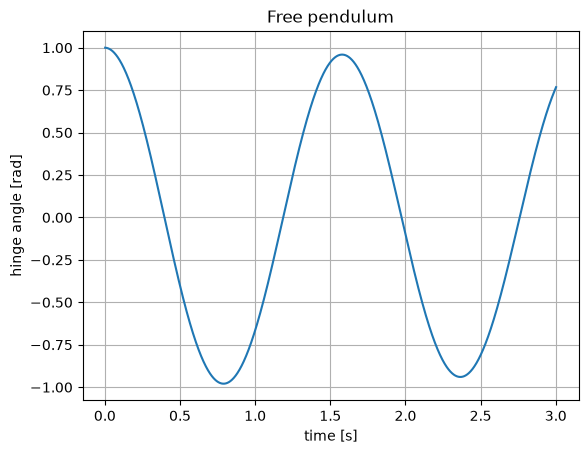

In [5]:
mujoco.mj_resetData(model, data)  # back to the initial state (t = 0, everything at rest)
data.qpos[0] = 1.0                # initial angle: 1 rad

times, angles = [], []
while data.time < 3.0:
    mujoco.mj_step(model, data)
    times.append(data.time)
    angles.append(data.qpos[0])

plt.plot(times, angles)
plt.xlabel("time [s]"); plt.ylabel("hinge angle [rad]"); plt.title("Free pendulum")
plt.grid(); plt.show()

That's a full simulation! Notice that it ran much faster than 3 real seconds: **MuJoCo has no notion of real time**. It computes as fast as it can, and keeping it in sync with the wall clock is the viewer's job (see section 6).

> 🧪 **Try it**
> - Change `damping="0.05"` in the XML to `0.5` and re-run sections 1.2 and 1.3. What happens?
> - Set `gravity="0 0 -1.62"` (the Moon). How does the period change?
> - Start at `data.qpos[0] = 3.0` (almost upside down).

---
## 2. Reading data

`MjData` holds the full state. The most useful fields:

| Field | Meaning |
|---|---|
| `data.time` | simulation time [s] |
| `data.qpos` | joint positions (angles for hinges) |
| `data.qvel` | joint velocities |
| `data.ctrl` | actuator commands (you write these) |
| `data.xpos`, `data.xquat` | position and orientation of every body in world coordinates |
| `data.site_xpos` | position of every site |
| `data.sensordata` | all sensor readings, concatenated |

### 2.1 Access by name

Indexing raw arrays (`data.qpos[7]`) gets confusing quickly. Use **named accessors** instead:

In [6]:
print("hinge angle   :", data.joint("hinge").qpos)
print("hinge velocity:", data.joint("hinge").qvel)
print("pole position :", data.body("pole").xpos)  # where the body frame is (the pivot)
print("tip position  :", data.site("tip").xpos)

# Sensors, by name
print("sensor angle  :", data.sensor("angle").data)
print("sensor tip    :", data.sensor("tip_position").data)

hinge angle   : [0.7674487]
hinge velocity: [2.04144581]
pole position : [0.  0.  1.5]
tip position  : [-0.41481432  0.          1.06649212]
sensor angle  : [0.76336581]
sensor tip    : [-0.41481432  0.          1.06649212]


The same works on the model, for constant properties:

In [7]:
print("ball radius   :", model.geom("ball").size[0])
print("pole mass     :", model.body("pole").mass[0], "kg")
print("hinge damping :", model.joint("hinge").damping[0])

ball radius   : 0.08
pole mass     : 3.954217953318353 kg
hinge damping : 0.05


### 2.2 ⚠️ `mj_forward`: when derived quantities are stale

`qpos` and `qvel` are the true state. Everything else (`xpos`, `site_xpos`, `sensordata`, …) is **computed from them** during a step. If you change `qpos` by hand, the derived quantities won't update until you call `mj_forward` (it computes everything without advancing time).

In [8]:
mujoco.mj_resetData(model, data)
data.qpos[0] = np.pi / 2  # put the pole horizontal

print("tip before mj_forward:", data.site("tip").xpos)  # still zeros: not computed yet
mujoco.mj_forward(model, data)
print("tip after  mj_forward:", data.site("tip").xpos)  # 0.6 m to the side of the pivot

tip before mj_forward: [0. 0. 0.]
tip after  mj_forward: [-0.6  0.   1.5]


### 2.3 Recording a trajectory

The usual pattern is to step and log what you need into lists, then convert to numpy:

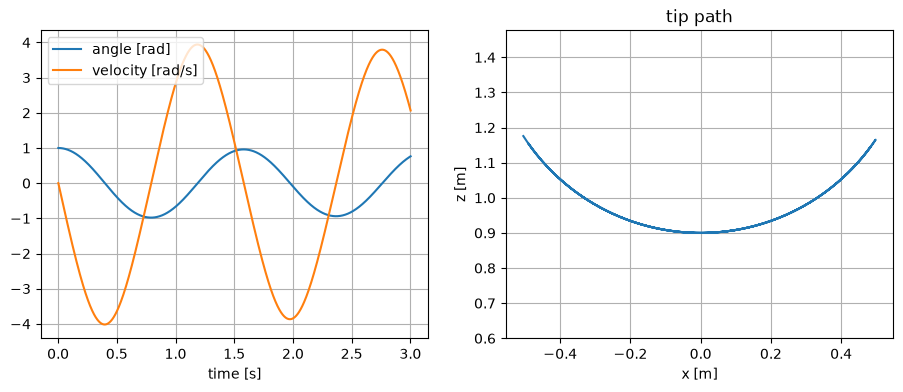

In [9]:
mujoco.mj_resetData(model, data)
data.qpos[0] = 1.0

log = {"t": [], "angle": [], "velocity": [], "tip": []}
while data.time < 3.0:
    mujoco.mj_step(model, data)
    log["t"].append(data.time)
    log["angle"].append(data.sensor("angle").data[0])
    log["velocity"].append(data.sensor("angular_velocity").data[0])
    log["tip"].append(data.sensor("tip_position").data.copy())  # .copy()! data arrays are overwritten in place

tip = np.array(log["tip"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(log["t"], log["angle"], label="angle [rad]")
ax1.plot(log["t"], log["velocity"], label="velocity [rad/s]")
ax1.set_xlabel("time [s]"); ax1.legend(); ax1.grid()
ax2.plot(tip[:, 0], tip[:, 2])
ax2.set_xlabel("x [m]"); ax2.set_ylabel("z [m]"); ax2.set_title("tip path"); ax2.axis("equal"); ax2.grid()
plt.show()

> ⚠️ Arrays like `data.qpos` or `data.sensor(...).data` are **views** into MuJoCo's memory and get overwritten on every step. Always `.copy()` them when storing.

> 🧪 **Try it**: add a `<framelinvel name="tip_velocity" objtype="site" objname="tip"/>` sensor to the XML and plot the tip speed.

---
## 3. Rendering

`mujoco.Renderer` draws the scene offscreen and gives you a numpy RGB image. Each frame takes two steps: `update_scene` (take a snapshot of `data`) and `render`.

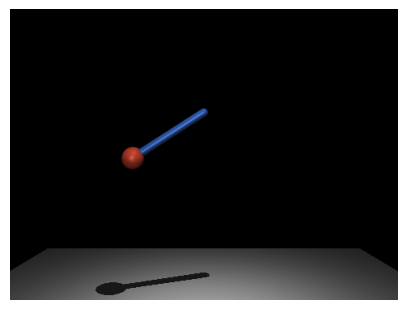

In [10]:
renderer = mujoco.Renderer(model, height=360, width=480)

mujoco.mj_resetData(model, data)
data.qpos[0] = 1.0
mujoco.mj_forward(model, data)  # make sure positions are up to date before drawing

renderer.update_scene(data, camera="front")  # camera defined in the XML
show(renderer.render())

A video is a list of frames. We don't need to render every physics step (500 per second here), just ~30 per second:

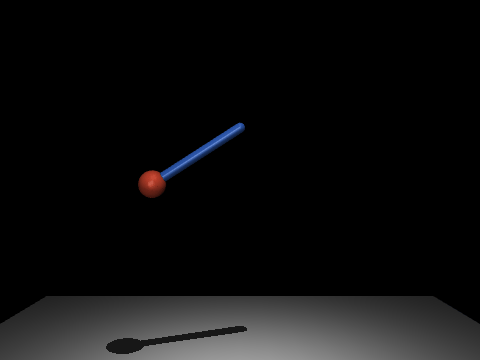

In [11]:
def simulate_and_record(model, data, duration, renderer, camera, fps=30, controller=None):
    # Step the simulation for `duration` seconds, optionally calling controller(model, data)
    # before every step, and return the rendered frames.
    frames = []
    while data.time < duration:
        if controller is not None:
            controller(model, data)
        mujoco.mj_step(model, data)
        if len(frames) < data.time * fps:
            renderer.update_scene(data, camera=camera)
            frames.append(renderer.render())
    return frames


mujoco.mj_resetData(model, data)
data.qpos[0] = 1.0
frames = simulate_and_record(model, data, duration=3.0, renderer=renderer, camera="front")
show_video(frames)

---
## 4. Actuating the system

So far nothing pushes the pendulum. To act on a system, MuJoCo uses **actuators**, declared in the XML. Each actuator reads **one number** from `data.ctrl`, and MuJoCo turns it into a force or torque.

The two most common types:

| Actuator | `ctrl` means | Force applied |
|---|---|---|
| `<motor>` | a torque/force (scaled by `gear`) | `gear * ctrl` |
| `<position>` | a **target position**: MuJoCo runs a built-in PD controller (a servo) | `kp * (ctrl - q) - kv * q̇` |

`ctrlrange` clamps the command to `[min, max]`, like a real motor's limits.

Models are just XML strings, so we write a small helper that adds an `<actuator>` block to the pendulum and builds a new model:

In [12]:
MOTOR = '<motor name="torque" joint="hinge" gear="1" ctrlrange="-20 20"/>'
SERVO = '<position name="servo" joint="hinge" kp="100" kv="10" ctrlrange="-3.14 3.14"/>'

def pendulum_with(actuator_xml):
    xml = PENDULUM_XML.replace("</mujoco>", f"<actuator>{actuator_xml}</actuator></mujoco>")
    model = mujoco.MjModel.from_xml_string(xml)
    return model, mujoco.MjData(model)

model, data = pendulum_with(MOTOR)
print("nu:", model.nu)
print("actuator 0:", model.actuator(0).name, " ctrlrange =", model.actuator_ctrlrange[0])

nu: 1
actuator 0: torque  ctrlrange = [-20.  20.]


### 4.1 Motor: apply a torque

We hold a constant torque of 8 Nm. The pendulum swings up and oscillates around the angle where gravity's torque balances the motor's (about 0.47 rad). Damping is very small, so it takes a long time to settle.

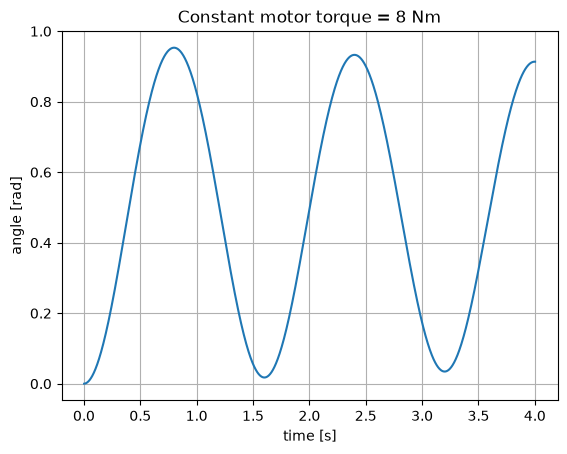

In [13]:
model, data = pendulum_with(MOTOR)
data.actuator("torque").ctrl = 8.0  # write the command once; it stays until you change it

t, q = [], []
while data.time < 4.0:
    mujoco.mj_step(model, data)
    t.append(data.time); q.append(data.qpos[0])

plt.plot(t, q); plt.xlabel("time [s]"); plt.ylabel("angle [rad]")
plt.title("Constant motor torque = 8 Nm"); plt.grid(); plt.show()

> 🧪 **Try it**: what is the smallest torque that can hold the pendulum horizontal? Can you lift it all the way to upside down?

### 4.2 Position actuator: send a target angle

With a `<position>` actuator, `ctrl` is the angle we want. Let's ask for 90° (π/2 rad):

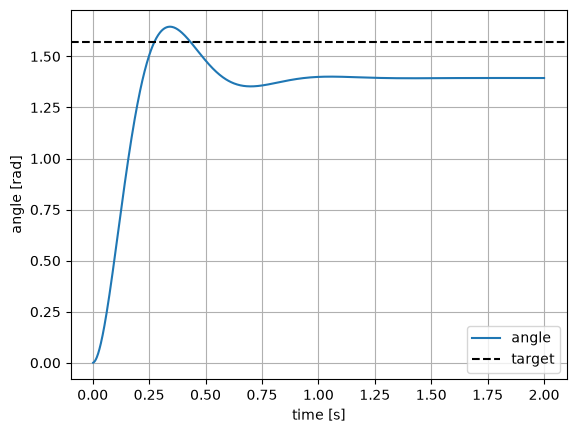

final error: 10.1 deg


In [14]:
model, data = pendulum_with(SERVO)
target = np.pi / 2
data.actuator("servo").ctrl = target

t, q = [], []
while data.time < 2.0:
    mujoco.mj_step(model, data)
    t.append(data.time); q.append(data.qpos[0])

plt.plot(t, q, label="angle")
plt.axhline(target, color="k", ls="--", label="target")
plt.xlabel("time [s]"); plt.ylabel("angle [rad]"); plt.legend(); plt.grid(); plt.show()
print(f"final error: {np.degrees(target - q[-1]):.1f} deg")

It doesn't quite reach the target. That's the classic **steady-state error** of a PD controller fighting gravity: it needs an error to produce torque.

> 🧪 **Try it**: change `kp` in `SERVO` to `500` and re-run. The error shrinks. What happens to the motion?

### 4.3 Your own control loop

Usually you compute the command yourself from the current state, **every step**. This is the core pattern of any robot controller (and of `src/sim.py`):

```
loop:
    read state      (data.qpos, data.qvel, data.sensordata)
    compute command
    write data.ctrl
    mj_step
```

Here we use the raw `torque` motor and write a PD controller that adds **gravity compensation** to remove the steady-state error. We also make the target change over time.

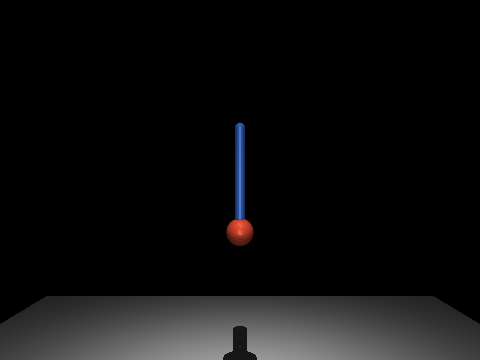

In [15]:
KP, KD = 60.0, 8.0

def target_angle(t):
    return np.pi / 2 if t < 2.0 else -np.pi / 4  # step change at t = 2 s

def my_controller(model, data):
    q = data.sensor("angle").data[0]                 # 1. read
    qd = data.sensor("angular_velocity").data[0]
    # 2. compute: PD + gravity compensation.
    # qfrc_bias holds the torques gravity (and Coriolis) apply at each joint;
    # the motor pushes back with the same amount.
    tau = KP * (target_angle(data.time) - q) - KD * qd + data.qfrc_bias[0]
    data.actuator("torque").ctrl = tau               # 3. write (clamped to ctrlrange by MuJoCo)

model, data = pendulum_with(MOTOR)
renderer.close()  # a Renderer belongs to one model: free the old one before creating a new one
renderer = mujoco.Renderer(model, height=360, width=480)
frames = simulate_and_record(model, data, duration=4.0, renderer=renderer, camera="front",
                             controller=my_controller)
show_video(frames)

> 🧪 **Try it**
> - Remove `+ data.qfrc_bias[0]` and see the steady-state error come back.
> - Make the target a sine wave: `return np.sin(2 * t)`.
> - Lower the `ctrlrange` in `MOTOR` to `-5 5`. Can it still lift the pendulum?

---
## 5. A real robot: the Shadow Hand

Writing XML by hand is fine for toy models. For real robots, use [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie), a collection of high-quality models. The `mujoco-menagerie` Python package downloads and loads them for you:

In [16]:
import mujoco_menagerie as mm

hand = mm.load("shadow_hand")  # returns a regular mujoco.MjModel
hand_data = mujoco.MjData(hand)

print("nq:", hand.nq, " nv:", hand.nv, " nu:", hand.nu, " timestep:", hand.opt.timestep)

nq: 31  nv: 30  nu: 20  timestep: 0.002


Same API as the pendulum, just bigger. `nq = 31` = 24 hand joints + 7 for the free-floating **object** (3 position + 4 quaternion) that rests above the palm.

### 5.1 Exploring the model

When you get a new model, list its joints and actuators first:

In [17]:
print(f"{'#':>2}  {'actuator':12s} {'drives':8s} {'target':10s} {'ctrlrange':>18s}")
for i in range(hand.nu):
    act = hand.actuator(i)
    is_tendon = hand.actuator_trntype[i] == mujoco.mjtTrn.mjTRN_TENDON
    target = hand.tendon(act.trnid[0]).name if is_tendon else hand.joint(act.trnid[0]).name
    lo, hi = act.ctrlrange
    print(f"{i:2d}  {act.name:12s} {'tendon' if is_tendon else 'joint':8s} {target:10s} [{lo:7.3f}, {hi:7.3f}]")

 #  actuator     drives   target              ctrlrange
 0  lh_A_WRJ2    joint    lh_WRJ2    [ -0.524,   0.175]
 1  lh_A_WRJ1    joint    lh_WRJ1    [ -0.698,   0.489]
 2  lh_A_THJ5    joint    lh_THJ5    [ -1.047,   1.047]
 3  lh_A_THJ4    joint    lh_THJ4    [  0.000,   1.222]
 4  lh_A_THJ3    joint    lh_THJ3    [ -0.209,   0.209]
 5  lh_A_THJ2    joint    lh_THJ2    [ -0.698,   0.698]
 6  lh_A_THJ1    joint    lh_THJ1    [ -0.262,   1.571]
 7  lh_A_FFJ4    joint    lh_FFJ4    [ -0.349,   0.349]
 8  lh_A_FFJ3    joint    lh_FFJ3    [ -0.262,   1.571]
 9  lh_A_FFJ0    tendon   lh_FFJ0    [  0.000,   3.142]
10  lh_A_MFJ4    joint    lh_MFJ4    [ -0.349,   0.349]
11  lh_A_MFJ3    joint    lh_MFJ3    [ -0.262,   1.571]
12  lh_A_MFJ0    tendon   lh_MFJ0    [  0.000,   3.142]
13  lh_A_RFJ4    joint    lh_RFJ4    [ -0.349,   0.349]
14  lh_A_RFJ3    joint    lh_RFJ3    [ -0.262,   1.571]
15  lh_A_RFJ0    tendon   lh_RFJ0    [  0.000,   3.142]
16  lh_A_LFJ5    joint    lh_LFJ5    [  0.000,  

All 20 are **position actuators**, so `ctrl` is a target angle in radians. Note the `*J0` actuators: each finger's two last joints (J1 + J2) are coupled through a **tendon**, as on the real hand, so one actuator flexes both. That's why there are 24 joints but only 20 actuators.

`shadow_hand_specs.json` at the root of this repo holds the same ranges, generated by `src/save_joint_ranges.py`.

### 5.2 Look at it

The model has no named cameras, so we use a **free camera** and place it by hand:

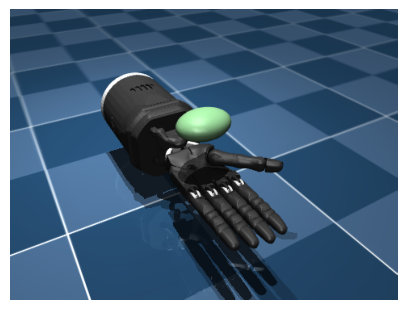

In [18]:
hand_renderer = mujoco.Renderer(hand, height=360, width=480)

cam = mujoco.MjvCamera()
cam.lookat[:] = [0.3, 0.0, 0.05]  # point to look at [m]
cam.distance = 0.5                 # [m]
cam.azimuth = 150                  # horizontal angle [deg]
cam.elevation = -35                # vertical angle [deg]

mujoco.mj_resetData(hand, hand_data)
mujoco.mj_forward(hand, hand_data)
hand_renderer.update_scene(hand_data, camera=cam)
show(hand_renderer.render())

### 5.3 Make a fist

We set target angles on the flexion actuators by name and let physics run for 2 seconds. While the fingers close, the object falls into the palm and gets grasped. Contacts are handled automatically.

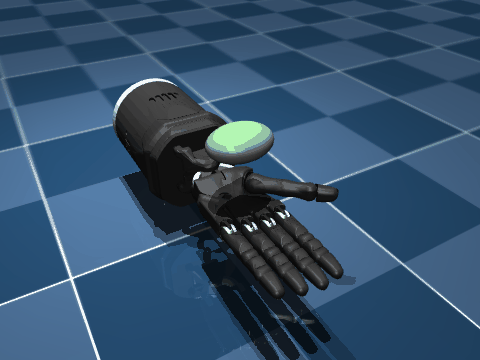

In [19]:
FIST = {
    # finger base flexion (J3) and coupled J1+J2 tendons (J0)
    "lh_A_FFJ3": 1.5, "lh_A_MFJ3": 1.5, "lh_A_RFJ3": 1.5, "lh_A_LFJ3": 1.5,
    "lh_A_FFJ0": 3.0, "lh_A_MFJ0": 3.0, "lh_A_RFJ0": 3.0, "lh_A_LFJ0": 3.0,
    # thumb
    "lh_A_THJ5": 0.5, "lh_A_THJ4": 1.2, "lh_A_THJ1": 1.5,
}

mujoco.mj_resetData(hand, hand_data)
for name, value in FIST.items():
    hand_data.actuator(name).ctrl = value

log = {"t": [], "FFJ3": [], "FFJ2": [], "FFJ1": []}
frames = []
while hand_data.time < 2.0:
    mujoco.mj_step(hand, hand_data)
    log["t"].append(hand_data.time)
    for j in ("FFJ3", "FFJ2", "FFJ1"):
        log[j].append(hand_data.joint("lh_" + j).qpos[0])
    if len(frames) < hand_data.time * 30:
        hand_renderer.update_scene(hand_data, camera=cam)
        frames.append(hand_renderer.render())

show_video(frames)

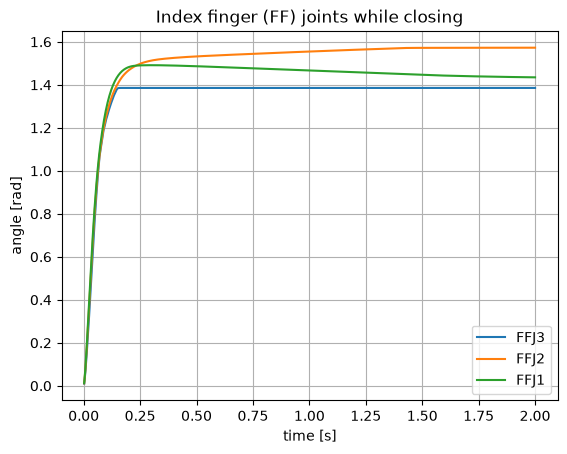

index fingertip position: [0.32827693 0.03283922 0.05440269]
object position         : [ 0.27402292 -0.00502245  0.04527951]
contacts right now      : 8


In [20]:
for j in ("FFJ3", "FFJ2", "FFJ1"):
    plt.plot(log["t"], log[j], label=j)
plt.xlabel("time [s]"); plt.ylabel("angle [rad]"); plt.title("Index finger (FF) joints while closing")
plt.legend(); plt.grid(); plt.show()

print("index fingertip position:", hand_data.body("lh_ffdistal").xpos)
print("object position         :", hand_data.body("object").xpos)
print("contacts right now      :", hand_data.ncon)

> 🧪 **Try it**
> - Comment out the thumb lines in `FIST`. Does the object still stay in the hand?
> - Close only the index finger (FF) and the thumb: a pinch.
> - Print `hand_data.contact[i].geom1/geom2` for a few contacts and look up their names with `hand.geom(id).name`.

### 5.4 Normalized commands (what `src/sim.py` does)

Each actuator has a different range, which is awkward for an external controller (or a neural network). The simulator in this repo accepts **normalized commands in `[0, 1]`** and maps them linearly to each actuator's range: `0 → min`, `1 → max`.

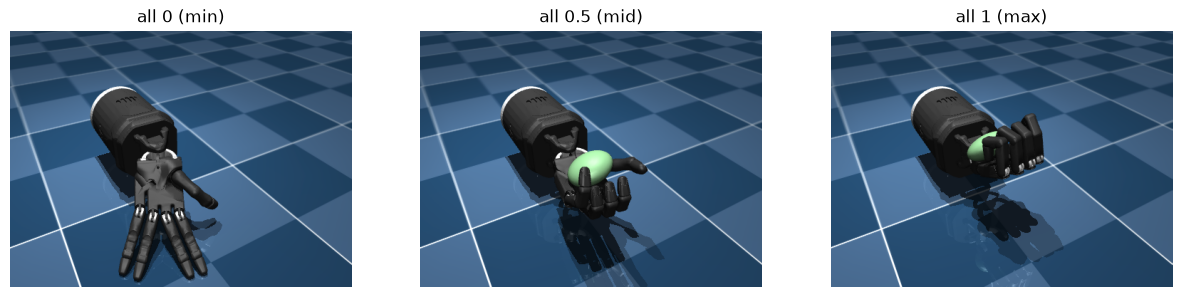

In [21]:
ctrl_min, ctrl_max = hand.actuator_ctrlrange.T  # one row per actuator

def decode_controls(normalized):
    # Map normalized [0, 1] controls to each actuator's real range (same as src/sim.py).
    normalized = np.clip(np.asarray(normalized), 0.0, 1.0)
    return ctrl_min + normalized * (ctrl_max - ctrl_min)

mujoco.mj_resetData(hand, hand_data)
poses = {"all 0 (min)": np.zeros(hand.nu), "all 0.5 (mid)": np.full(hand.nu, 0.5), "all 1 (max)": np.ones(hand.nu)}
images = []
for name, normalized in poses.items():
    mujoco.mj_resetData(hand, hand_data)
    hand_data.ctrl[:] = decode_controls(normalized)
    mujoco.mj_step(hand, hand_data, nstep=1000)  # nstep: run 1000 steps in one call (2 s)
    hand_renderer.update_scene(hand_data, camera=cam)
    images.append(hand_renderer.render())

show(*images, titles=list(poses))

---
## 6. Cheat sheet

```python
# Load
model = mujoco.MjModel.from_xml_path("robot.xml")   # or .from_xml_string(xml), or mm.load("name")
data  = mujoco.MjData(model)

# Simulate
mujoco.mj_resetData(model, data)      # reset to initial state
mujoco.mj_forward(model, data)        # recompute derived quantities, no time advance
mujoco.mj_step(model, data)           # advance one timestep (model.opt.timestep)
mujoco.mj_step(model, data, nstep=n)  # advance n timesteps

# Read
data.time, data.qpos, data.qvel, data.sensordata
data.joint("name").qpos     data.body("name").xpos     data.site("name").xpos
data.sensor("name").data    data.ncon, data.contact

# Act
data.ctrl[i] = value
data.actuator("name").ctrl = value
model.actuator_ctrlrange    # [nu, 2] min/max per actuator

# Render
r = mujoco.Renderer(model, height, width)
r.update_scene(data, camera="name" or MjvCamera or index)
img = r.render()            # (height, width, 3) uint8
```

## 8. Where to go next

- 📖 [MuJoCo documentation](https://mujoco.readthedocs.io): start with *Overview* and *Python bindings*.
- 📖 [XML reference (MJCF)](https://mujoco.readthedocs.io/en/stable/XMLreference.html): every tag and attribute.
- 📓 [Official MuJoCo tutorial notebook](https://github.com/google-deepmind/mujoco/blob/main/python/tutorial.ipynb): goes deeper into rendering, contacts and more.
- 🤖 [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie): ready-to-use robot models.